# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name: Kanwal Gul
- **Student ID:** 023-24-0001
- **Section:** B
- **GitHub:** 
- **Kaggle:**
- **Dataset:** Telco Customer Churn (Kaggle)
- **Dataset Source:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn/code  

---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.


---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [1]:
import warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, auc, precision_recall_curve, average_precision_score)

RANDOM_STATE = 42

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Raw shape:", df.shape)

# TotalCharges has blank strings -> coerce to NaN, then fill (blank rows are new customers with tenure 0)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())
df["TotalCharges"] = df["TotalCharges"].fillna(0)

df = df.drop(columns=["customerID"])
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
print("Churn rate:", round(df["Churn"].mean(), 4))
df.head()

Raw shape: (7043, 21)
Missing TotalCharges: 11
Churn rate: 0.2654


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [2]:
X = pd.get_dummies(df.drop(columns=["Churn"]), drop_first=True).astype(float)
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("X shape:", X.shape)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train churn rate:", round(y_train.mean(), 4), " Test churn rate:", round(y_test.mean(), 4))

X shape: (7043, 30)
Train: (5634, 30)  Test: (1409, 30)
Train churn rate: 0.2654  Test churn rate: 0.2654


---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [3]:
# Unscaled linear SVM. max_iter is capped so a non-converging solver cannot hang the notebook;
# if the cap is hit, scikit-learn raises a ConvergenceWarning which we record.
with warnings.catch_warnings(record=True) as w_raw:
    warnings.simplefilter("always")
    t0 = time.time()
    svm_raw = SVC(kernel="linear", random_state=RANDOM_STATE, max_iter=2_000_000)
    svm_raw.fit(X_train, y_train)
    time_raw = time.time() - t0
pred_raw = svm_raw.predict(X_test)
acc_raw, f1_raw = accuracy_score(y_test, pred_raw), f1_score(y_test, pred_raw)
print(f"UNSCALED  accuracy={acc_raw:.4f}  F1={f1_raw:.4f}  train time={time_raw:.2f}s")
print("Warnings:", [str(w.message)[:90] for w in w_raw] or "none")

UNSCALED  accuracy=0.6508  F1=0.5138  train time=42.49s
Warnings: ['Solver terminated early (max_iter=2000000).  Consider pre-processing your data with Standa']


In [4]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit on TRAIN only
X_test_s = scaler.transform(X_test)         # transform only on TEST

with warnings.catch_warnings(record=True) as w_s:
    warnings.simplefilter("always")
    t0 = time.time()
    svm_scaled = SVC(kernel="linear", random_state=RANDOM_STATE)
    svm_scaled.fit(X_train_s, y_train)
    time_scaled = time.time() - t0
pred_s = svm_scaled.predict(X_test_s)
acc_s, f1_s = accuracy_score(y_test, pred_s), f1_score(y_test, pred_s)
print(f"SCALED    accuracy={acc_s:.4f}  F1={f1_s:.4f}  train time={time_scaled:.2f}s")
print("Warnings:", [str(w.message)[:90] for w in w_s] or "none")

pd.DataFrame({"Accuracy": [acc_raw, acc_s], "F1": [f1_raw, f1_s],
              "Train time (s)": [time_raw, time_scaled],
              "Warnings": [len(w_raw), len(w_s)]}, index=["Unscaled", "Scaled"]).round(4)

SCALED    accuracy=0.7885  F1=0.5694  train time=1.77s
Warnings: none


,Accuracy,F1,Train time (s),Warnings
Unscaled,0.6508,0.5138,42.4855,1
Scaled,0.7885,0.5694,1.7724,0


**Questions to answer:**
(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?

*Your answer:* **Unscaled:** accuracy 0.6508, F1 0.5138, training time 42.49 s, and a `ConvergenceWarning` ("Solver terminated early") because the solver did not converge. Note: I capped `max_iter` at 2,000,000 so the notebook could not hang; without that cap the run may take far longer.
**Scaled:** accuracy 0.7885, F1 0.5694, training time 1.77 s, no warnings.
Scaling gained +13.8 points of accuracy and +0.056 F1, and training was about 24x faster.

(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?

*Your answer:* A linear SVM looks for the hyperplane w·x + b = 0 that maximises the margin 2/||w||, and it measures distance in plain Euclidean space. Unscaled `TotalCharges` (0 to about 8,700), `MonthlyCharges` (about 18 to 119) and `tenure` (0 to 72) are orders of magnitude larger than the 0/1 dummy columns, so they dominate every dot product and distance. For a 0/1 feature to influence the boundary, its weight would have to be huge, and the penalty on ||w||² discourages that, so the margin is decided almost entirely by the big-scale features. The wide range of scales also makes the optimisation badly conditioned, which explains the slow, non-converging solver and the weak accuracy.

(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?

*Your answer:* I use the **scaled** version (`StandardScaler` fitted on the training set only, then applied to train and test) for every SVM from here on. It is clearly better on accuracy, F1 and speed, and fitting on train only avoids leaking test-set statistics. RBF and polynomial kernels also depend on distances or dot products, so they need scaling just as much.


---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [5]:
def evaluate(name, model, Xtr, Xte):
    t0 = time.time()
    model.fit(Xtr, y_train)
    t = time.time() - t0
    p = model.predict(Xte)
    return {"Kernel": name,
            "Accuracy": accuracy_score(y_test, p),
            "Precision": precision_score(y_test, p),
            "Recall": recall_score(y_test, p),
            "F1": f1_score(y_test, p),
            "Support vectors": model.support_.shape[0],
            "SV per class (0/1)": tuple(model.n_support_),
            "Train time (s)": t}

kernel_models = {k: SVC(kernel=k, random_state=RANDOM_STATE) for k in ["linear", "rbf", "poly"]}
kernel_rows = [evaluate(k, m, X_train_s, X_test_s) for k, m in kernel_models.items()]
print("Trained linear, rbf and poly SVMs on the scaled split.")

Trained linear, rbf and poly SVMs on the scaled split.


In [6]:
kernel_table = pd.DataFrame(kernel_rows).set_index("Kernel")
display(kernel_table.round(4))
best_kernel = kernel_table["F1"].idxmax()
print("Best kernel by F1:", best_kernel)

,Accuracy,Precision,Recall,F1,Support vectors,SV per class (0/1),Train time (s)
Kernel,,,,,,,
linear,0.7885,0.6195,0.5267,0.5694,2567,"(1286, 1281)",1.5338
rbf,0.7928,0.6444,0.4893,0.5562,2657,"(1428, 1229)",1.1794
poly,0.7892,0.6421,0.4652,0.5395,2736,"(1482, 1254)",0.9719


Best kernel by F1: linear


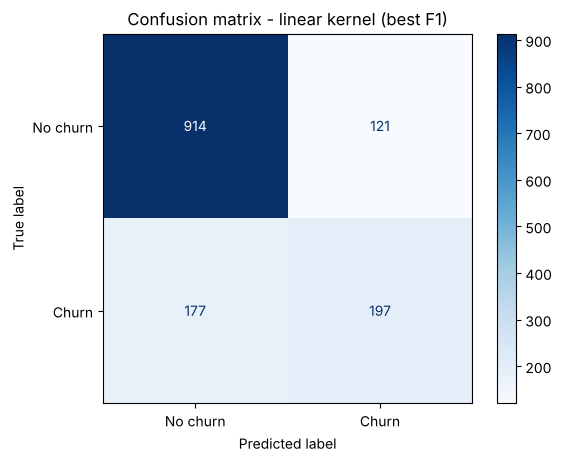

[[914 121]
 [177 197]]


In [7]:
best_model = kernel_models[best_kernel]
cm = confusion_matrix(y_test, best_model.predict(X_test_s))
ConfusionMatrixDisplay(cm, display_labels=["No churn", "Churn"]).plot(cmap="Blues")
plt.title(f"Confusion matrix - {best_kernel} kernel (best F1)")
plt.show()
print(cm)

**Interpretation:** The linear SVM (best F1) correctly identifies 197 of the 374 churners (recall 0.527) and misses 177. It also raises 121 false alarms among the 1,035 loyal customers, and gets 914 of them right. The model is better at recognising loyal customers than churners, which is typical for imbalanced data where the majority class dominates the loss.

**Questions to answer:**
(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?

*Your answer:* **Linear** gave the best F1 (0.5694), ahead of RBF (0.5562) and poly (0.5395). Mild surprise: the theory says RBF is the more flexible kernel and often wins, but here it only wins on accuracy (0.7928 vs 0.7885) and precision (0.6444 vs 0.6195). Linear wins because it has higher recall (0.5267 vs 0.4893). After one-hot encoding there are 30 features and the churn signal is largely linear (contract type, tenure, internet service). The gaps are small (about 0.01 to 0.03 F1 on 1,409 test rows), so they should not be over-interpreted.

(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?

*Your answer:* **Poly** used the most support vectors (2,736), then RBF (2,657) and linear (2,567). That is roughly 46% to 49% of the 5,634 training rows. A support-vector count this high means the two classes overlap heavily (many points sit inside or on the wrong side of the margin) and that the boundary cannot be described by a small set of "critical" points. The polynomial kernel has the most support vectors and the lowest F1, which suggests the extra complexity is not buying better generalisation.

(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.

*Your answer:* I carry the **RBF kernel** forward, for these reasons. It has the highest accuracy (0.7928) and precision (0.6444), and its F1 (0.5562) is only 0.0132 below the best untuned model. It has two hyperparameters (C and gamma) that were left at defaults here, so it has the most tuning headroom. Poly is the worst on F1 (0.5395) and recall (0.4652) and has the most support vectors, so I drop it. Linear had the best untuned F1, so a tuned linear model is a legitimate baseline, but Part 4 is specified as a C x gamma search, which only RBF supports.


---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [8]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=RANDOM_STATE)
Z_train = pca.fit_transform(X_train_s)
Z_test = pca.transform(X_test_s)
print("Explained variance ratio per component:", pca.explained_variance_ratio_.round(4))
print("Total explained variance (2 components):", round(pca.explained_variance_ratio_.sum(), 4))

Explained variance ratio per component: [0.3325 0.1198]
Total explained variance (2 components): 0.4522


In [9]:
C_values = [0.01, 1, 100]
pca_models = {}
for c in C_values:
    m = SVC(kernel="rbf", C=c, gamma="scale", random_state=RANDOM_STATE)
    m.fit(Z_train, y_train)
    pca_models[c] = m
    print(f"C={c:<6} support vectors={m.support_.shape[0]:<5} "
          f"train acc={m.score(Z_train, y_train):.4f}  test acc={m.score(Z_test, y_test):.4f}")

C=0.01   support vectors=2995  train acc=0.7346  test acc=0.7346


C=1      support vectors=2658  train acc=0.7792  test acc=0.7786


C=100    support vectors=2641  train acc=0.7813  test acc=0.7793


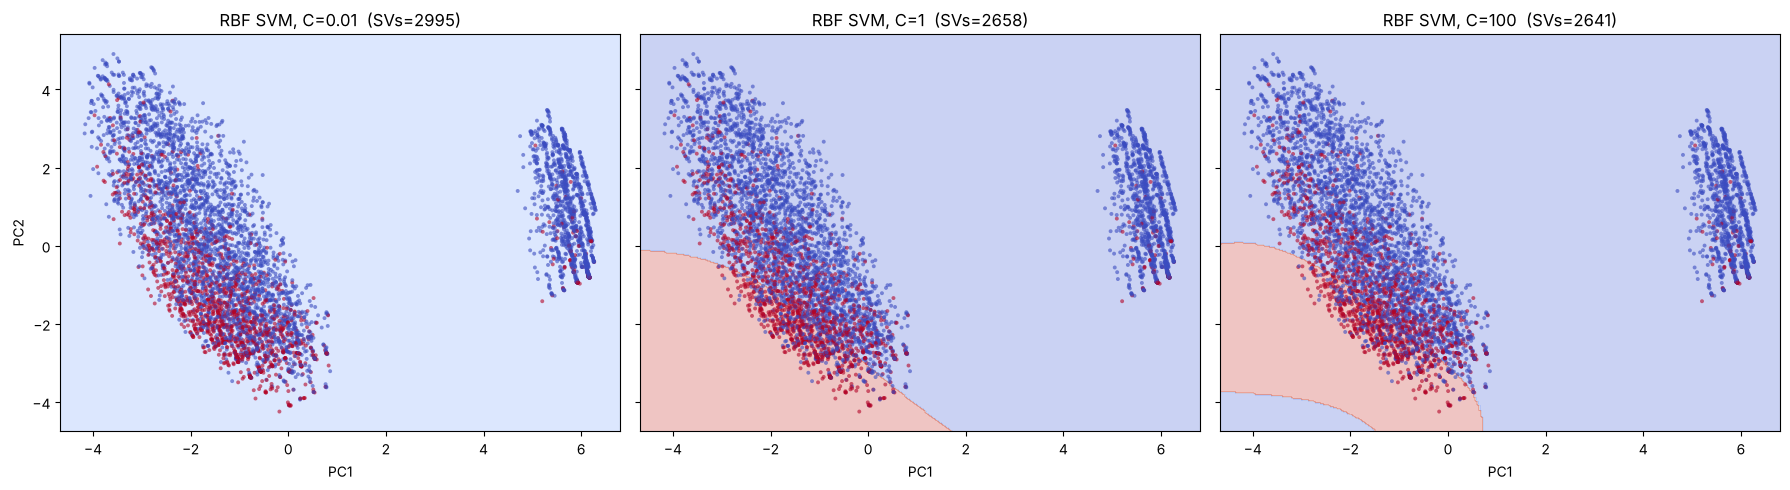

In [10]:
pad = 0.5
x_min, x_max = Z_train[:, 0].min() - pad, Z_train[:, 0].max() + pad
y_min, y_max = Z_train[:, 1].min() - pad, Z_train[:, 1].max() + pad
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
for ax, c in zip(axes, C_values):
    m = pca_models[c]
    Zg = m.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Zg, alpha=0.3, cmap="coolwarm")
    ax.scatter(Z_train[:, 0], Z_train[:, 1], c=y_train, cmap="coolwarm", s=8, edgecolor="none", alpha=0.6)
    ax.set_title(f"RBF SVM, C={c}  (SVs={m.support_.shape[0]})")
    ax.set_xlabel("PC1")
axes[0].set_ylabel("PC2")
plt.tight_layout()
plt.show()

**Interpretation:** C = 0.01 is a single flat region (everything predicted "No churn"). At C = 1 a smooth red region covers the lower-left where red (churn) points concentrate, and at C = 100 that region is a little larger and more curved, with a small extra pocket in the corner. The boundary gets more flexible as C increases, but because the classes overlap strongly in this 2-D view no boundary separates them cleanly. The isolated cluster on the right (customers with no internet service) is almost entirely blue (non-churn).

**Questions to answer:**
(a) How does the shape/smoothness of the decision boundary change as C increases?

*Your answer:* At **C = 0.01** there is effectively no boundary: the whole plane is one class (predict "No churn"). At **C = 1** a smooth, single rounded red "churn" region appears in the lower-left, where red training points are concentrated. At **C = 100** the red region grows and its edge becomes more curved, with a small separate pocket forming in the bottom-left corner. As C increases, the boundary goes from non-existent, to smooth, to more flexible and wiggly.

(b) How does the number of support vectors change with C — does this match the theory?

*Your answer:* Support vectors drop with C: **2,995 (C=0.01) → 2,658 (C=1) → 2,641 (C=100)**. This matches the theory: a small C allows many margin violations (wide, soft margin), so most points become support vectors, and a large C penalises violations heavily, so fewer points stay inside the margin. The drop from C=1 to C=100 is tiny (17 points) because the classes overlap so much in 2-D that violators cannot be removed however high C goes.

(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.

*Your answer:* **Underfitting: C = 0.01.** Its train and test accuracy are both 0.7346, which is exactly the majority-class rate (1 − 0.2654), and the plot shows one flat colour, so it ignores the churners entirely. **Closest to overfitting: C = 100,** which has the most flexible boundary (curved edge plus a small pocket), although the numbers show only a mild effect (train 0.7813 vs test 0.7793, a gap of only 0.002). So in this 2-D view the problem is mainly underfitting at small C, and there is no strong overfitting even at C=100. C=1 is a good balance.

(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?

*Your answer:* The 2-D plot is only an approximation for these reasons. (1) PCA keeps only **45.2%** of the variance (PC1 33.3% + PC2 12.0%), so more than half of the information is discarded, and points that overlap here may be separable in the original 30 dimensions. (2) These SVMs are trained *on the projection*; they are different models from the real 30-D SVM, not a slice of it. (3) PCA directions maximise variance, not class separation. For example, the isolated cluster on the right (1,214 training points, all with `InternetService_No`, churn rate only 7.2% vs 31.8% for the rest) drives PC1 but says little about churn boundaries. (4) The shaded regions extend into empty space where the model is only extrapolating. The plot is good for intuition about C, but it can mislead about how well, or how complexly, the real model separates the classes.


---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [11]:
param_grid = {"C": [0.1, 1, 10, 100],
              "gamma": [0.0001, 0.001, 0.01, 0.1]}
t0 = time.time()
gs = GridSearchCV(SVC(kernel="rbf", random_state=RANDOM_STATE), param_grid,
                  cv=5, scoring="f1", n_jobs=-1)
gs.fit(X_train_s, y_train)
print(f"Grid search finished in {time.time() - t0:.1f}s")
print("Best params:", gs.best_params_)
print("Best mean CV F1:", round(gs.best_score_, 4))

Grid search finished in 44.1s
Best params: {'C': 100, 'gamma': 0.0001}
Best mean CV F1: 0.5882


,0.0001,0.0010,0.0100,0.1000
0.1,0.0000,0.0000,0.5417,0.4640
1.0,0.0000,0.5739,0.5652,0.5734
10.0,0.5777,0.5836,0.5860,0.5270
100.0,0.5882,0.5706,0.5876,0.5061


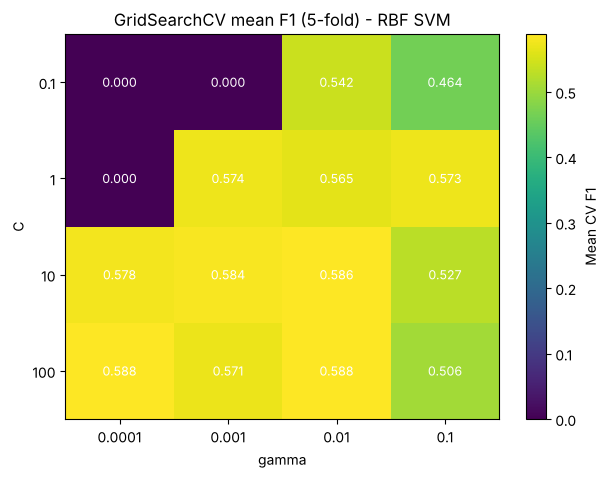

In [12]:
scores = gs.cv_results_["mean_test_score"].reshape(len(param_grid["C"]), len(param_grid["gamma"]))
heat = pd.DataFrame(scores, index=param_grid["C"], columns=param_grid["gamma"])
display(heat.round(4))

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(scores, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(param_grid["gamma"])), param_grid["gamma"])
ax.set_yticks(range(len(param_grid["C"])), param_grid["C"])
ax.set_xlabel("gamma"); ax.set_ylabel("C")
for i in range(scores.shape[0]):
    for j in range(scores.shape[1]):
        ax.text(j, i, f"{scores[i, j]:.3f}", ha="center", va="center", color="white", fontsize=9)
plt.colorbar(im, label="Mean CV F1")
ax.set_title("GridSearchCV mean F1 (5-fold) - RBF SVM")
plt.show()

**Interpretation:** The brightest cells (F1 around 0.58 to 0.59) form a diagonal ridge where larger C pairs with smaller gamma. The dark cells in the top-left (C = 0.1 or 1 with very small gamma) are 0.000, meaning the model predicts no churners at all. The bottom-right (C = 100, gamma = 0.1) drops to 0.506 because of overfitting. The best cell (C = 100, gamma = 0.0001) sits on the grid edge, so the true optimum could be slightly beyond it.

In [13]:
best_rbf = gs.best_estimator_            # already refit on the full training set
p_tuned = best_rbf.predict(X_test_s)
tuned = {"Accuracy": accuracy_score(y_test, p_tuned), "Precision": precision_score(y_test, p_tuned),
         "Recall": recall_score(y_test, p_tuned), "F1": f1_score(y_test, p_tuned)}
untuned = kernel_table.loc["rbf", ["Accuracy", "Precision", "Recall", "F1"]].to_dict()
display(pd.DataFrame({"Untuned RBF (Part 2)": untuned, "Tuned RBF (GridSearchCV)": tuned}).T.round(4))
print("CV F1 (best):", round(gs.best_score_, 4), "| Test F1:", round(tuned["F1"], 4))

,Accuracy,Precision,Recall,F1
Untuned RBF (Part 2),0.7928,0.6444,0.4893,0.5562
Tuned RBF (GridSearchCV),0.7942,0.6338,0.5321,0.5785


CV F1 (best): 0.5882 | Test F1: 0.5785


**Questions to answer:**
(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?

*Your answer:* Best parameters: **C = 100, gamma = 0.0001**, with a mean 5-fold CV F1 of **0.5882**. Caveat: both values sit on the edge of my grid (largest C, smallest gamma), so a wider grid might find slightly better values.

(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?

*Your answer:* There is no sharp peak; there is a **broad plateau**. Many combinations score between about 0.577 and 0.588 (for example C=10, gamma=0.01 gives 0.5860; C=100, gamma=0.01 gives 0.5876), and the best cell beats them by less than 0.001, which is within CV noise. The good cells form a diagonal ridge (larger C pairs with smaller gamma). The top-left corner (small C and small gamma) scores **0.000** because the model is so smooth that it predicts "No churn" for everyone, and large C with large gamma (C=100, gamma=0.1: 0.506) falls off because the model overfits. So the model is not very sensitive to the exact choice anywhere on the ridge, and the exact "best" cell should not be over-trusted.

(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?

*Your answer:* They agree closely: CV F1 0.5882 vs test F1 **0.5785**, a gap of about 0.01. This suggests that the tuning has not overfit the validation folds. A large gap (test much lower than CV) would suggest overfitting to the CV folds (selection bias from searching many settings), a small or unrepresentative test set, or leakage in the CV pipeline.

(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?

*Your answer:* Tuning gave a modest but real improvement on the test set. F1 rose from 0.5562 to **0.5785** (+0.022), recall from 0.4893 to 0.5321 (+0.043), accuracy from 0.7928 to 0.7942 (+0.001), while precision dipped from 0.6444 to 0.6338 (−0.011). It cost only 44.1 s, so it was worth doing, mostly for the recall gain, but it is not a dramatic improvement.


---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Accuracy,Precision,Recall,F1
Model,,,,
class_weight=None,0.7942,0.6338,0.5321,0.5785
class_weight='balanced',0.6941,0.4575,0.8209,0.5876


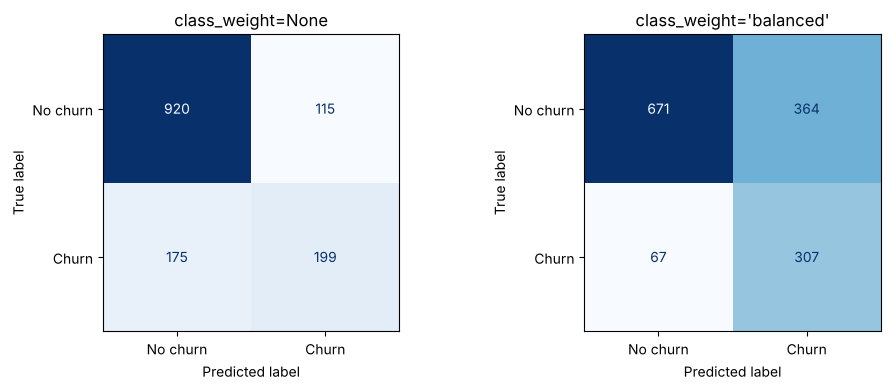

class_weight=None -> TN, FP, FN, TP = [920 115 175 199]
class_weight='balanced' -> TN, FP, FN, TP = [671 364  67 307]


In [14]:
best_C, best_gamma = gs.best_params_["C"], gs.best_params_["gamma"]
cw_models = {
    "class_weight=None": SVC(kernel="rbf", C=best_C, gamma=best_gamma, class_weight=None,
                             probability=True, random_state=RANDOM_STATE),
    "class_weight='balanced'": SVC(kernel="rbf", C=best_C, gamma=best_gamma, class_weight="balanced",
                                   probability=True, random_state=RANDOM_STATE),
}
cw_rows, cw_cms = [], {}
for name, m in cw_models.items():
    m.fit(X_train_s, y_train)
    p = m.predict(X_test_s)
    cw_cms[name] = confusion_matrix(y_test, p)
    cw_rows.append({"Model": name, "Accuracy": accuracy_score(y_test, p),
                    "Precision": precision_score(y_test, p), "Recall": recall_score(y_test, p),
                    "F1": f1_score(y_test, p)})
display(pd.DataFrame(cw_rows).set_index("Model").round(4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, cmx) in zip(axes, cw_cms.items()):
    ConfusionMatrixDisplay(cmx, display_labels=["No churn", "Churn"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()
for n, cmx in cw_cms.items():
    print(n, "-> TN, FP, FN, TP =", cmx.ravel())

**Interpretation:** The weighted model (right) catches far more churners (307 true positives vs 199) and misses far fewer (67 false negatives vs 175), but flags many more loyal customers by mistake (364 false positives vs 115). It is the better detector of churn and the worse one for accuracy and precision.

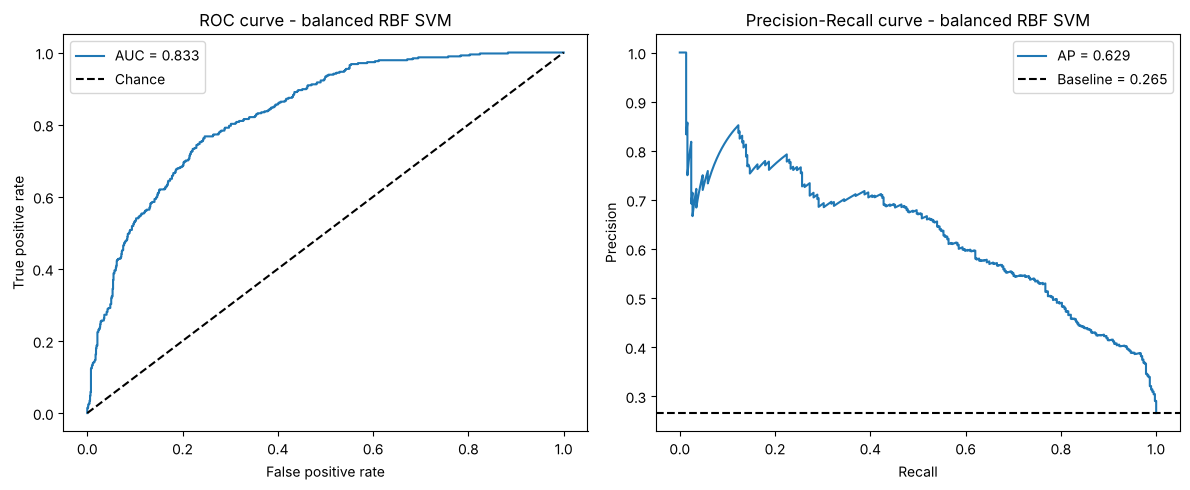

ROC AUC = 0.8327 | Average precision = 0.6295


In [15]:
bal = cw_models["class_weight='balanced'"]
proba_bal = bal.predict_proba(X_test_s)[:, 1]

fpr, tpr, _ = roc_curve(y_test, proba_bal)
prec, rec, _ = precision_recall_curve(y_test, proba_bal)
roc_auc, ap = auc(fpr, tpr), average_precision_score(y_test, proba_bal)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], "k--", label="Chance")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curve - balanced RBF SVM"); axes[0].legend()
axes[1].plot(rec, prec, label=f"AP = {ap:.3f}")
axes[1].axhline(y_test.mean(), color="k", ls="--", label=f"Baseline = {y_test.mean():.3f}")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall curve - balanced RBF SVM"); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"ROC AUC = {roc_auc:.4f} | Average precision = {ap:.4f}")

**Interpretation:** The ROC curve stays well above the chance diagonal (AUC = 0.833), so the model ranks churners above non-churners most of the time. The precision-recall curve (average precision 0.630 vs a no-skill baseline of 0.265) shows precision falling as recall rises. The balanced model's operating point (recall 0.82, precision 0.46) sits on the steep part of the curve, where each extra churner caught costs a lot of precision.

**Questions to answer:**
(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.

*Your answer:* Switching from `class_weight=None` to `'balanced'`: **precision fell from 0.6338 to 0.4575 (−0.176)** and **recall rose from 0.5321 to 0.8209 (+0.289)**. F1 rose slightly from 0.5785 to 0.5876 (+0.009) and accuracy fell from 0.7942 to 0.6941. In the confusion matrix, false negatives dropped from 175 to 67 (108 more churners caught), but false positives rose from 115 to 364 (249 more false alarms).

(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?

*Your answer:* In most subscription businesses a missed churner (false negative) costs more, because it is lost recurring revenue, whereas a false positive usually costs only a retention offer or a call to someone who would have stayed. The numbers give a break-even: balanced catches 108 more churners for 249 more false alarms, so it is better when one missed churner costs more than **249 / 108 ≈ 2.3 times** one false alarm. I would deploy the **balanced model** for a retention campaign. If the offers are expensive (for example big discounts), the cost ratio could fall below 2.3, and the unweighted model would then be the better choice. I do not have actual cost figures, so this threshold is the real decision point.

(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?

*Your answer:* You must set **`probability=True`** in `SVC()`. This makes scikit-learn fit a Platt-scaling calibration (a logistic regression on the SVM scores, using internal 5-fold cross-validation), which makes training slower, and the probabilities can occasionally disagree with `predict()`. Alternatively, `decision_function()` gives an uncalibrated score without the extra cost. Note that in the scikit-learn version here (1.9.1) the `probability` parameter shows a FutureWarning (deprecated; `CalibratedClassifierCV(SVC(), ensemble=False)` is the suggested replacement).


---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [16]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

# Same split as everywhere else. Scale-sensitive models (LogReg, KNN, SVM) use scaled data; trees use raw.
showdown = {
    "Decision Tree": (DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE), False),
    "Random Forest": (RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1), False),
    "Logistic Regression": (LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), True),
    "KNN": (KNeighborsClassifier(n_neighbors=11), True),
    "SVM (tuned RBF, balanced)": (SVC(kernel="rbf", C=best_C, gamma=best_gamma, class_weight="balanced",
                                       random_state=RANDOM_STATE), True),
}
rows = []
for name, (m, use_scaled) in showdown.items():
    Xtr, Xte = (X_train_s, X_test_s) if use_scaled else (X_train.values, X_test.values)
    t0 = time.time(); m.fit(Xtr, y_train); t = time.time() - t0
    p = m.predict(Xte)
    rows.append({"Model": name, "Accuracy": accuracy_score(y_test, p), "Precision": precision_score(y_test, p),
                 "Recall": recall_score(y_test, p), "F1": f1_score(y_test, p), "Train time (s)": t})
showdown_table = pd.DataFrame(rows).set_index("Model")
display(showdown_table.round(4))
print("Best F1:", showdown_table["F1"].idxmax(), "| Best recall:", showdown_table["Recall"].idxmax())

,Accuracy,Precision,Recall,F1,Train time (s)
Model,,,,,
Decision Tree,0.7942,0.6312,0.5401,0.5821,0.0139
Random Forest,0.7928,0.6367,0.5107,0.5668,0.9098
Logistic Regression,0.8070,0.6584,0.5668,0.6092,0.0490
KNN,0.7729,0.5758,0.5481,0.5616,0.0030
"SVM (tuned RBF, balanced)",0.6941,0.4575,0.8209,0.5876,1.6933


Best F1: Logistic Regression | Best recall: SVM (tuned RBF, balanced)


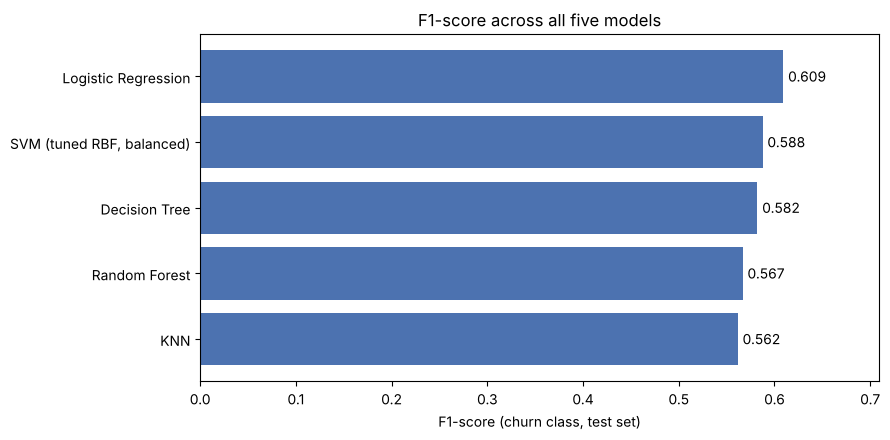

In [17]:
ordered = showdown_table["F1"].sort_values()
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(ordered.index, ordered.values, color="#4C72B0")
for b, v in zip(bars, ordered.values):
    ax.text(v + 0.005, b.get_y() + b.get_height() / 2, f"{v:.3f}", va="center")
ax.set_xlabel("F1-score (churn class, test set)")
ax.set_title("F1-score across all five models")
ax.set_xlim(0, ordered.max() + 0.1)
plt.tight_layout(); plt.show()

**Interpretation:** Logistic Regression has the highest F1 (0.609), followed by the balanced SVM (0.588), the Decision Tree (0.582), Random Forest (0.567) and KNN (0.562). All five models fall within about 0.05 F1 of each other, so F1 alone does not separate them strongly. The balanced SVM's value shows up in recall (0.82), which F1 hides.

**Questions to answer:**
(a) Which model wins on F1-score? Which wins on recall? Are they the same model?

*Your answer:* **Logistic Regression wins on F1 (0.6092)**, and it also has the best accuracy (0.8070) and precision (0.6584). **The balanced SVM wins on recall (0.8209)**. So they are not the same model: the best F1 model and the best recall model differ because the balanced SVM trades precision (0.4575) for recall.

(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?

*Your answer:* Not really in terms of F1. The tuned, balanced SVM (F1 0.5876) is below Logistic Regression (0.6092) and about level with the Decision Tree (0.5821), while taking about 1.7 s to train (plus 44.1 s for the grid search) against 0.02 s for the tree and 0.05 s for Logistic Regression. Its real advantage is the **recall of 0.82** from `class_weight='balanced'`. I did not test whether Logistic Regression or the tree with the same class weighting would reach similar recall, so I cannot say the SVM is the only way to get it. Also note that the other models were not tuned (depth 5 tree, 200-tree forest, k=11 KNN), so the comparison favours the tuned SVM if anything.

(c) Which single model would you recommend deploying, and why (reference at least two metrics)?

*Your answer:* I would deploy the **balanced RBF SVM**, because it has by far the highest recall (**0.8209**, with 307 of 374 churners caught), an F1 of **0.5876** that is within 0.022 of the best model, and a ROC AUC of 0.833. This choice depends on the Part 5 cost argument (a missed churner costing more than about 2.3 false alarms). If false alarms are costly instead, **Logistic Regression** is the better and simpler model (F1 0.6092, accuracy 0.8070, precision 0.6584, training in 0.05 s).


---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [18]:
final_model = cw_models["class_weight='balanced'"]     # tuned RBF SVM with balanced class weights
scores_test = final_model.predict_proba(X_test_s)[:, 1]
preds = final_model.predict(X_test_s)

out = pd.DataFrame({"true_label": y_test.values,
                    "predicted_label": preds,
                    "churn_probability": scores_test.round(4)}, index=y_test.index)
out.index.name = "row_index"
out.to_csv("svm_predictions.csv")
print("Saved svm_predictions.csv with", len(out), "rows")
out.head()

Saved svm_predictions.csv with 1409 rows


,true_label,predicted_label,churn_probability
row_index,,,
437,0,0,0.1026
2280,0,1,0.4784
2235,0,0,0.1021
4460,0,1,0.4747
3761,0,0,0.1017


**Executive Summary**

I chose the tuned RBF SVM (C = 100, gamma = 0.0001) with `class_weight='balanced'` as the final churn model. On the 1,409-row held-out test set it reaches recall 0.821, precision 0.458, F1 0.588 and accuracy 0.694, with a ROC AUC of 0.833. Scaling features was essential (unscaled linear SVM: accuracy 0.651 and no convergence vs 0.789 scaled). The main trade-off from Part 5 is that balancing the classes raised recall by 0.289 but cut precision by 0.176, catching 108 more churners at the cost of 249 more false alarms, which pays off if a missed churner costs more than about 2.3 false alarms. Logistic Regression had a higher F1 (0.609) and accuracy (0.807) at the default threshold, so it is the better pick if false alarms are expensive. One limitation is that I evaluated on a single train/test split with lightly configured baseline models and no real cost data, so the ranking of models and the 2.3 break-even are indicative rather than definitive.

**Final Reflection**
(a) What was the single most surprising result in this lab?

*Your answer:* The most surprising result was how little the kernel mattered: the untuned linear SVM had the best F1 of the three kernels, and Logistic Regression beat the tuned RBF SVM on F1. I was also surprised that C = 0.01 (and small C with small gamma in the grid) produced a model that predicts "No churn" for everyone, which scores accuracy 0.7346 but F1 of 0.

(b) If you had one more hour, what would you try next?

*Your answer:* I would (1) extend the grid beyond its edges (C > 100, gamma < 0.0001), since the best values sat on the boundary; (2) give every model the same treatment (tuning plus class weights) and use repeated stratified CV instead of a single split; and (3) tune the decision threshold on predicted probability using real cost numbers for retention offers vs lost customers.
